# Perceptron vs Neural Networks

Comparing single-layer perceptron and multi-layer neural networks on classification tasks.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Machine%20learning/Latent%20Variable%20Models%20and%20Neural%20Networks%2091/Perceptron%20vs%20Neural%20Networks.ipynb)

# **Perceptron vs Neural Networks**

In [ ]:
from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier


**I Load Task2B train.csv and Task2B test.csv datasets, plot the training and testing data sep- arately in two plots. Mark the data with different labels in different colors.**

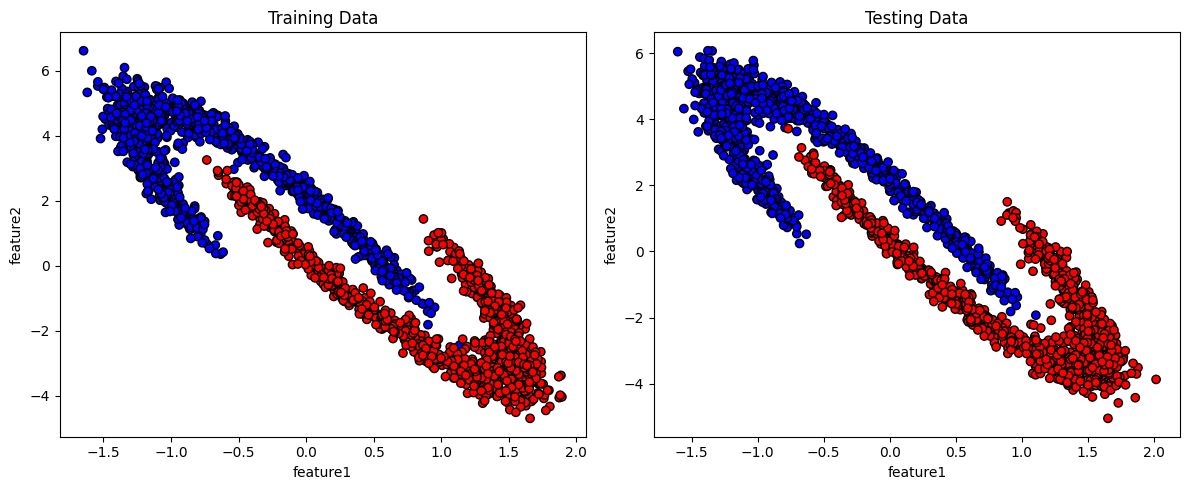

In [ ]:
# Load data
train_df = pd.read_csv('Task2B_train (2).csv')
test_df = pd.read_csv('Task2B_test (2).csv')

# Extract X and y
X_train = train_df[['feature1', 'feature2']].values
y_train = train_df['label'].values
X_test = test_df[['feature1', 'feature2']].values
y_test = test_df['label'].values

# Plot training data
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr', edgecolor='k')
plt.title("Training Data")
plt.xlabel("feature1")
plt.ylabel("feature2")

# Plot testing data
plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr', edgecolor='k')
plt.title("Testing Data")
plt.xlabel("feature1")
plt.ylabel("feature2")
plt.tight_layout()
plt.show()


**II Train two Perceptron models on the loaded training data by setting the learning rates η to 0.1 and 1.0 respectively. Calculate the test errors of two models and find the best η and its corresponding model, then plot the decision boundary and the test data in one plot. We expect the decision boundary of perceptron to be a linear function that separates the testing data into two parts. we may also choose to change the labels from [0, 1] to [-1, +1] for our convenience.**

Test errors: eta=0.1: 0.125, eta=1.0: 0.125
Best eta: 0.1


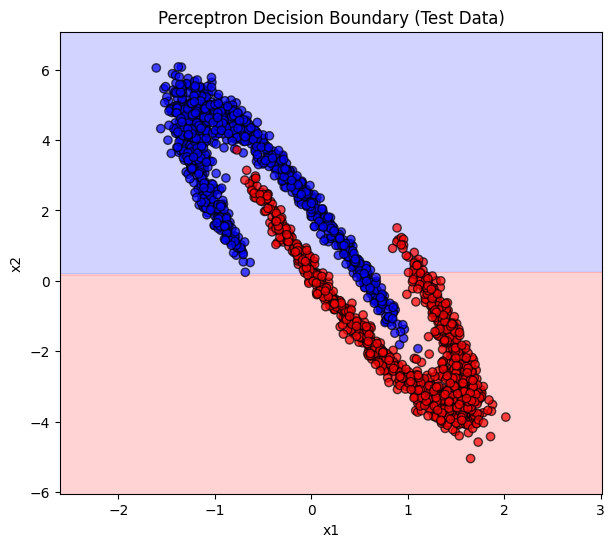

In [ ]:
# Train perceptrons with different learning rates
perceptrons = []
test_errors = []
for eta in [0.1, 1.0]:
    clf = Perceptron(eta0=eta, max_iter=1000, tol=1e-3, random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    error = 1 - accuracy_score(y_test, y_pred)
    perceptrons.append(clf)
    test_errors.append(error)

best_idx = np.argmin(test_errors)
best_eta = [0.1, 1.0][best_idx]
best_clf = perceptrons[best_idx]

print(f"Test errors: eta=0.1: {test_errors[0]:.3f}, eta=1.0: {test_errors[1]:.3f}")
print(f"Best eta: {best_eta}")

# Plot decision boundary
def plot_decision_boundary(clf, X, y):
    x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
    y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(7,6))
    plt.contourf(xx, yy, Z, alpha=0.2, cmap='bwr')
    plt.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolor='k', alpha=0.7)
    plt.title('Perceptron Decision Boundary (Test Data)')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.show()

plot_decision_boundary(best_clf, X_test, y_test)

**For each combination of K (i.e, number of units in the hidden layer) in 5, 10, 15, ..., 40, (i.e. from 5 to 40 with a step size of 5), and η (i.e., learning rate) in 0.01, 0.001 run the 3-layer Neural Network and record testing error for each of them. Plot the effect of different K values on the accuracy of the testing data. Based on this plot, find the best combination of K and η and obtain our best model, then plot the decision boundary and the test data in one plot.**

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


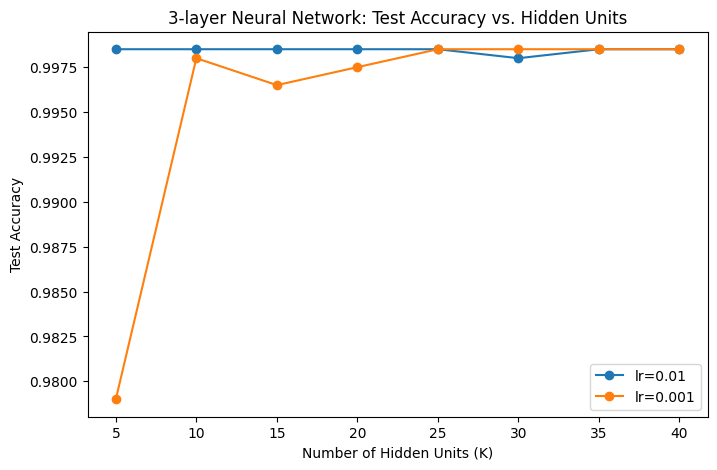

Best K: 5, Best lr: 0.01, Test Error: 0.001


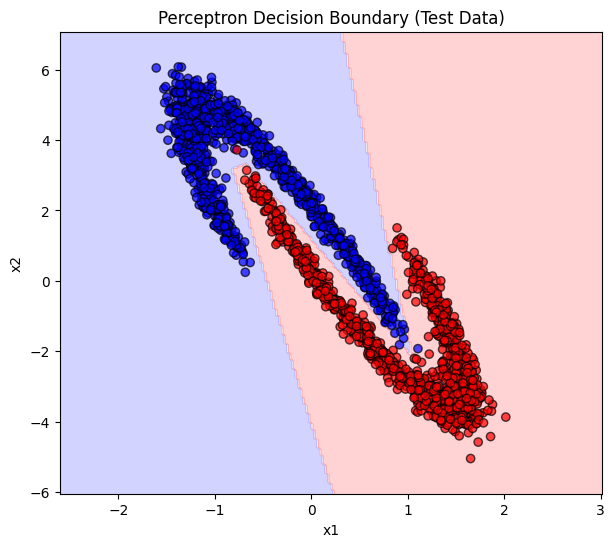

In [ ]:
hidden_units = list(range(5, 41, 5))
learning_rates = [0.01, 0.001]
results = []

for K in hidden_units:
    for lr in learning_rates:
        mlp = MLPClassifier(hidden_layer_sizes=(K,), activation='relu', solver='adam', learning_rate_init=lr, max_iter=1000, random_state=42)
        mlp.fit(X_train, y_train)
        y_pred = mlp.predict(X_test)
        error = 1 - accuracy_score(y_test, y_pred)
        results.append({'K': K, 'lr': lr, 'error': error})

# Convert to DataFrame for plotting
results_df = pd.DataFrame(results)

# Plot effect of K on accuracy (for each learning rate)
plt.figure(figsize=(8,5))
for lr in learning_rates:
    subset = results_df[results_df['lr']==lr]
    plt.plot(subset['K'], 1-subset['error'], marker='o', label=f'lr={lr}')
plt.xlabel('Number of Hidden Units (K)')
plt.ylabel('Test Accuracy')
plt.title('3-layer Neural Network: Test Accuracy vs. Hidden Units')
plt.legend()
plt.show()

# Find best model
best_row = results_df.loc[results_df['error'].idxmin()]
best_K, best_lr = int(best_row['K']), best_row['lr']
print(f"Best K: {best_K}, Best lr: {best_lr}, Test Error: {best_row['error']:.3f}")

# Train best model and plot decision boundary
best_mlp = MLPClassifier(hidden_layer_sizes=(best_K,), activation='relu', solver='adam',
                         learning_rate_init=best_lr, max_iter=1000, random_state=42)
best_mlp.fit(X_train, y_train)
plot_decision_boundary(best_mlp, X_test, y_test)


**the reason(s) responsible for such difference between Perceptron and a 3-layer Neural Network by comparing the plots we generated.**

The key difference between the Perceptron and the 3-layer Neural Network, as shown in your plots, is due to their model assumptions and capacity to represent decision boundaries.

- Perceptron:  
  The perceptron is a linear classifier. Its decision boundary is always a straight line (or a hyperplane in higher dimensions). In plots, the perceptron creates a linear boundary that cannot fully separate the two curved clusters, resulting in misclassified points along the boundary. This limitation is because the perceptron can only solve problems where the classes are linearly separable.

- 3-layer Neural Network:  
  The 3-layer neural network (a multilayer perceptron with one hidden layer) can learn nonlinear decision boundaries by applying nonlinear activation functions in the hidden layer. In plot, the neural network’s decision boundary curves to fit the true shape of the data, accurately separating the two classes even when they are not linearly separable. This flexibility comes from the network’s ability to combine multiple nonlinear transformations.

The perceptron cannot fit complex, non-linear patterns in the data due to its linear nature, while the 3-layer neural network can adapt its decision boundary to the data’s structure, leading to better classification performance when the true boundary is nonlinear. This is visually evident in plots: the neural network’s boundary closely follows the data, while the perceptron’s is always straight.

